### hostplital operations & patient experience analyics

## business goal

### the hostipal wants to understand:

### who are our patients
### which departments are overlpaded ?
### where are waiting-time problem heppening ?
### does waiting time affect satisfaction ?
### which service types anf payer group create the highest financial burden ?
### what action should management take ?


## how we will work

### for every analysis we follw the same analyst workflow:

## business problem --> analysis --> result --> obsevation --> insight --> recommendation 

### the recommensation is written only after looking at the result .

## 1. imp liabraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

## 2. load the data 

In [2]:
patients = pd.read_csv(r"patients.csv")
visits = pd.read_csv(r"visits.csv")
billing = pd.read_csv(r"billing.csv")


In [3]:
print("patients:" ,patients.shape)
print("visits", visits.shape)
print("billing: ", billing.shape)

patients: (4010, 10)
visits (12015, 10)
billing:  (12015, 9)


# 3.basic data understanding 

## business purpose

### before cleanign , first understand :

#### numbers of rows
#### data types
#### missing values 
#### duplicates records

In [4]:
print("\n patients")
display (patients.head())
patients.info()


 patients


,patient_id,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date
0,100001,Patient_100001,Male,39,Hyderabad,NaN,Insured,NaN,30.9,2023-11-20
1,100002,Patient_100002,Male,49,Hyderabad,A+,Government Scheme,Thyroid,18.4,2023-07-04
2,100003,Patient_100003,Female,23,Karimnagar,B+,Insured,NaN,17.8,2022-06-24
3,100004,Patient_100004,female,52,Secunderabad,O+,Insured,Cardiac,20.4,2025-10-18
4,100005,Patient_100005,Male,41,Nizamabad,O-,Insured,Diabetes,21.5,2022-07-15


<class 'pandas.DataFrame'>
RangeIndex: 4010 entries, 0 to 4009
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patient_id         4010 non-null   int64  
 1   patient_name       4010 non-null   str    
 2   gender             4010 non-null   str    
 3   age                4010 non-null   int64  
 4   city               3961 non-null   str    
 5   blood_group        3969 non-null   str    
 6   insurance_status   4010 non-null   str    
 7   chronic_condition  2150 non-null   str    
 8   bmi                3930 non-null   float64
 9   registration_date  4010 non-null   str    
dtypes: float64(1), int64(2), str(7)
memory usage: 528.1 KB


In [5]:
display(billing.head())
billing.info()


,bill_id,visit_id,patient_id,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date
0,800001,500001,102866,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10
1,800002,500002,100602,1609.59,0.00,1609.59,Card,Paid,2025-01-23
2,800003,500003,102563,26915.56,22533.66,4381.90,Scheme,Partially Paid,2024-06-04
3,800004,500004,102617,20186.36,14645.71,5540.65,UPI,Paid,2024-06-30
4,800005,500005,100435,3098.79,2117.99,980.80,UPI,Paid,2025-04-11


<class 'pandas.DataFrame'>
RangeIndex: 12015 entries, 0 to 12014
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   bill_id                   12015 non-null  int64  
 1   visit_id                  12015 non-null  int64  
 2   patient_id                12015 non-null  int64  
 3   bill_amount               11865 non-null  float64
 4   insurance_covered_amount  11835 non-null  float64
 5   patient_paid_amount       11865 non-null  float64
 6   payment_method            11925 non-null  str    
 7   payment_status            12015 non-null  str    
 8   billing_date              12015 non-null  str    
dtypes: float64(3), int64(3), str(3)
memory usage: 1.1 MB


In [6]:
display(visits.head())
visits.info()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0


<class 'pandas.DataFrame'>
RangeIndex: 12015 entries, 0 to 12014
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   visit_id              12015 non-null  int64  
 1   patient_id            12015 non-null  int64  
 2   visit_date            12015 non-null  str    
 3   visit_hour            12015 non-null  int64  
 4   department            11975 non-null  str    
 5   diagnosis             11895 non-null  str    
 6   visit_type            12015 non-null  str    
 7   waiting_time_minutes  11835 non-null  float64
 8   length_of_stay_days   12015 non-null  float64
 9   satisfaction_score    11855 non-null  float64
dtypes: float64(3), int64(3), str(4)
memory usage: 1.4 MB


In [7]:
patients.head()

,patient_id,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date
0,100001,Patient_100001,Male,39,Hyderabad,NaN,Insured,NaN,30.9,2023-11-20
1,100002,Patient_100002,Male,49,Hyderabad,A+,Government Scheme,Thyroid,18.4,2023-07-04
2,100003,Patient_100003,Female,23,Karimnagar,B+,Insured,NaN,17.8,2022-06-24
3,100004,Patient_100004,female,52,Secunderabad,O+,Insured,Cardiac,20.4,2025-10-18
4,100005,Patient_100005,Male,41,Nizamabad,O-,Insured,Diabetes,21.5,2022-07-15


In [8]:
# replace the blank text with nan only in column where internally created

patients[["bmi" , "city" , "blood_group"]] = patients[["bmi" ,"city" ,"blood_group"]].replace("" , np.nan)

In [9]:
visits.head()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0


In [10]:
visits[['waiting_time_minutes','satisfaction_score','diagnosis','department']] = visits[['waiting_time_minutes','satisfaction_score','diagnosis','department']].replace("", np.nan) 

In [11]:
billing.head()
# billing.info()

,bill_id,visit_id,patient_id,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date
0,800001,500001,102866,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10
1,800002,500002,100602,1609.59,0.00,1609.59,Card,Paid,2025-01-23
2,800003,500003,102563,26915.56,22533.66,4381.90,Scheme,Partially Paid,2024-06-04
3,800004,500004,102617,20186.36,14645.71,5540.65,UPI,Paid,2024-06-30
4,800005,500005,100435,3098.79,2117.99,980.80,UPI,Paid,2025-04-11


In [12]:
billing[["bill_amount" , "insurance_covered_amount" ,"patients_paid_amount" , "payment_method"]] = billing[["bill_amount" ,"insurance_covered_amount" ,"patient_paid_amount" ,"payment_method"]].replace("" , np.nan)

In [13]:
patients.isnull().sum()

patient_id              0
patient_name            0
gender                  0
age                     0
city                   49
blood_group            41
insurance_status        0
chronic_condition    1860
bmi                    80
registration_date       0
dtype: int64

In [14]:
visits.isnull().sum()


visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department               40
diagnosis               120
visit_type                0
waiting_time_minutes    180
length_of_stay_days       0
satisfaction_score      160
dtype: int64

In [15]:
billing.isnull().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                 150
insurance_covered_amount    180
patient_paid_amount         150
payment_method               90
payment_status                0
billing_date                  0
patients_paid_amount        150
dtype: int64

In [16]:
# check the null values using for loop 

for table in [patients, visits , billing]:
    print("*****************")
    print(table.isnull().sum())

*****************
patient_id              0
patient_name            0
gender                  0
age                     0
city                   49
blood_group            41
insurance_status        0
chronic_condition    1860
bmi                    80
registration_date       0
dtype: int64
*****************
visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department               40
diagnosis               120
visit_type                0
waiting_time_minutes    180
length_of_stay_days       0
satisfaction_score      160
dtype: int64
*****************
bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                 150
insurance_covered_amount    180
patient_paid_amount         150
payment_method               90
payment_status                0
billing_date                  0
patients_paid_amount        150
dtype: int64


In [17]:
patients.info()

<class 'pandas.DataFrame'>
RangeIndex: 4010 entries, 0 to 4009
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patient_id         4010 non-null   int64  
 1   patient_name       4010 non-null   str    
 2   gender             4010 non-null   str    
 3   age                4010 non-null   int64  
 4   city               3961 non-null   str    
 5   blood_group        3969 non-null   str    
 6   insurance_status   4010 non-null   str    
 7   chronic_condition  2150 non-null   str    
 8   bmi                3930 non-null   float64
 9   registration_date  4010 non-null   str    
dtypes: float64(1), int64(2), str(7)
memory usage: 528.1 KB


In [18]:
# convert numeric columns back to numeric
patients["age"] = pd.to_numeric(patients["age"] , errors = "coerce")

In [19]:
patients["bmi"] = pd.to_numeric(patients["bmi"] , errors = "coerce")

In [20]:
visits.head()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0


In [21]:
visits.info()

<class 'pandas.DataFrame'>
RangeIndex: 12015 entries, 0 to 12014
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   visit_id              12015 non-null  int64  
 1   patient_id            12015 non-null  int64  
 2   visit_date            12015 non-null  str    
 3   visit_hour            12015 non-null  int64  
 4   department            11975 non-null  str    
 5   diagnosis             11895 non-null  str    
 6   visit_type            12015 non-null  str    
 7   waiting_time_minutes  11835 non-null  float64
 8   length_of_stay_days   12015 non-null  float64
 9   satisfaction_score    11855 non-null  float64
dtypes: float64(3), int64(3), str(4)
memory usage: 1.4 MB


In [22]:
visits["waiting_time_minutes"] = pd.to_numeric(visits["waiting_time_minutes"] , errors = "coerce")

In [23]:
visits["satisfaction_score"] = pd.to_numeric(visits["satisfaction_score"] , errors = "coerce")

In [24]:
visits["length_of_stay_days"] = pd.to_numeric(visits["length_of_stay_days"] , errors = "coerce")

In [25]:
billing.head()

,bill_id,visit_id,patient_id,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,patients_paid_amount
0,800001,500001,102866,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10,1776.91
1,800002,500002,100602,1609.59,0.00,1609.59,Card,Paid,2025-01-23,1609.59
2,800003,500003,102563,26915.56,22533.66,4381.90,Scheme,Partially Paid,2024-06-04,4381.90
3,800004,500004,102617,20186.36,14645.71,5540.65,UPI,Paid,2024-06-30,5540.65
4,800005,500005,100435,3098.79,2117.99,980.80,UPI,Paid,2025-04-11,980.80


In [26]:
billing.info()

<class 'pandas.DataFrame'>
RangeIndex: 12015 entries, 0 to 12014
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   bill_id                   12015 non-null  int64  
 1   visit_id                  12015 non-null  int64  
 2   patient_id                12015 non-null  int64  
 3   bill_amount               11865 non-null  float64
 4   insurance_covered_amount  11835 non-null  float64
 5   patient_paid_amount       11865 non-null  float64
 6   payment_method            11925 non-null  str    
 7   payment_status            12015 non-null  str    
 8   billing_date              12015 non-null  str    
 9   patients_paid_amount      11865 non-null  float64
dtypes: float64(4), int64(3), str(3)
memory usage: 1.2 MB


In [27]:
billing["bill_amount"] = pd.to_numeric(billing["bill_amount"] , errors = "coerce")

In [28]:
billing.info()

<class 'pandas.DataFrame'>
RangeIndex: 12015 entries, 0 to 12014
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   bill_id                   12015 non-null  int64  
 1   visit_id                  12015 non-null  int64  
 2   patient_id                12015 non-null  int64  
 3   bill_amount               11865 non-null  float64
 4   insurance_covered_amount  11835 non-null  float64
 5   patient_paid_amount       11865 non-null  float64
 6   payment_method            11925 non-null  str    
 7   payment_status            12015 non-null  str    
 8   billing_date              12015 non-null  str    
 9   patients_paid_amount      11865 non-null  float64
dtypes: float64(4), int64(3), str(3)
memory usage: 1.2 MB


In [29]:
billing['insurance_covered_amount'] = pd.to_numeric(billing['insurance_covered_amount'], errors='coerce')
billing['patient_paid_amount'] = pd.to_numeric(billing['patient_paid_amount'], errors='coerce')


# 4. Missing values and duplicates Audit

In [30]:
print(patients.info())

<class 'pandas.DataFrame'>
RangeIndex: 4010 entries, 0 to 4009
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patient_id         4010 non-null   int64  
 1   patient_name       4010 non-null   str    
 2   gender             4010 non-null   str    
 3   age                4010 non-null   int64  
 4   city               3961 non-null   str    
 5   blood_group        3969 non-null   str    
 6   insurance_status   4010 non-null   str    
 7   chronic_condition  2150 non-null   str    
 8   bmi                3930 non-null   float64
 9   registration_date  4010 non-null   str    
dtypes: float64(1), int64(2), str(7)
memory usage: 528.1 KB
None


In [31]:
display(patients.info())

<class 'pandas.DataFrame'>
RangeIndex: 4010 entries, 0 to 4009
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patient_id         4010 non-null   int64  
 1   patient_name       4010 non-null   str    
 2   gender             4010 non-null   str    
 3   age                4010 non-null   int64  
 4   city               3961 non-null   str    
 5   blood_group        3969 non-null   str    
 6   insurance_status   4010 non-null   str    
 7   chronic_condition  2150 non-null   str    
 8   bmi                3930 non-null   float64
 9   registration_date  4010 non-null   str    
dtypes: float64(1), int64(2), str(7)
memory usage: 528.1 KB


None

In [32]:
display(patients.isnull().sum())

patient_id              0
patient_name            0
gender                  0
age                     0
city                   49
blood_group            41
insurance_status        0
chronic_condition    1860
bmi                    80
registration_date       0
dtype: int64

In [33]:
for table in [patients , visits , billing]:
    print("***********************************")
    print(table.isnull().sum())

***********************************
patient_id              0
patient_name            0
gender                  0
age                     0
city                   49
blood_group            41
insurance_status        0
chronic_condition    1860
bmi                    80
registration_date       0
dtype: int64
***********************************
visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department               40
diagnosis               120
visit_type                0
waiting_time_minutes    180
length_of_stay_days       0
satisfaction_score      160
dtype: int64
***********************************
bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                 150
insurance_covered_amount    180
patient_paid_amount         150
payment_method               90
payment_status                0
billing_date                  0
patients_paid_amount        150
dtype:

In [34]:
for table in [patients, visits , billing]:
    print("*************************************")
    print(table.duplicated().sum())

*************************************
10
*************************************
15
*************************************
15


# 5. Data Cleaning

### we will keep the code simple
### the main idea is to choose the cleanign method based on the 
### relationship between columns instead of applaying one rule everywhere

# 5.1 clean patient data 

#### scenario 1 - duplicates rows

### exact duplicates can inflate patient counts , so remove them 

In [35]:
patients.shape

(4010, 10)

In [36]:
patients.count()

patient_id           4010
patient_name         4010
gender               4010
age                  4010
city                 3961
blood_group          3969
insurance_status     4010
chronic_condition    2150
bmi                  3930
registration_date    4010
dtype: int64

In [37]:
patients["patient_id"].unique()

array([100001, 100002, 100003, ..., 103998, 103999, 104000], shape=(4000,))

In [38]:
patients.duplicated().sum()

np.int64(10)

In [39]:
patients[patients.duplicated()]

,patient_id,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date
4000,100201,Patient_100201,Female,22,Warangal,B+,Self Pay,Thyroid,21.9,2024-07-25
4001,101079,Patient_101079,Male,19,Secunderabad,AB-,Self Pay,NaN,21.2,2022-05-22
4002,100611,Patient_100611,Female,61,Nizamabad,B+,Insured,NaN,24.0,2022-12-17
4003,102160,Patient_102160,Male,52,Nizamabad,A-,Insured,Cardiac,18.4,2023-02-04
4004,101170,Patient_101170,Male,60,Hyderabad,B-,Insured,Hypertension,33.3,2024-11-01
4005,102449,Patient_102449,Male,44,Hyderabad,O+,Insured,Asthma,26.9,2023-04-29
4006,102939,Patient_102939,Female,45,Warangal,B-,Self Pay,NaN,20.9,2022-08-15
4007,100814,Patient_100814,Female,58,Karimnagar,O+,Self Pay,Diabetes,21.4,2022-03-02
4008,101269,Patient_101269,Male,61,Warangal,NaN,Self Pay,NaN,30.1,2025-06-19
4009,100871,Patient_100871,Male,22,Hyderabad,B+,Insured,Diabetes,33.1,2024-05-01


In [40]:
patients=patients.drop_duplicates()

In [41]:
patients.duplicated().sum()

np.int64(0)

## scenario 2 - standardize gender and city

In [42]:
# if male , m, and Male are treated as different categories , our report become a wrong 


In [43]:
patients.head()

,patient_id,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date
0,100001,Patient_100001,Male,39,Hyderabad,NaN,Insured,NaN,30.9,2023-11-20
1,100002,Patient_100002,Male,49,Hyderabad,A+,Government Scheme,Thyroid,18.4,2023-07-04
2,100003,Patient_100003,Female,23,Karimnagar,B+,Insured,NaN,17.8,2022-06-24
3,100004,Patient_100004,female,52,Secunderabad,O+,Insured,Cardiac,20.4,2025-10-18
4,100005,Patient_100005,Male,41,Nizamabad,O-,Insured,Diabetes,21.5,2022-07-15


In [44]:
patients["city"].unique()

<ArrowStringArray>
[   'Hyderabad',   'Karimnagar', 'Secunderabad',    'Nizamabad',
            nan,     'Warangal',    'HYDERABAD',  ' hyderabad ']
Length: 8, dtype: str

In [45]:
patients["city"] = patients["city"].str.strip().str.title()

In [46]:
patients["city"].unique()

<ArrowStringArray>
['Hyderabad', 'Karimnagar', 'Secunderabad', 'Nizamabad', nan, 'Warangal']
Length: 6, dtype: str

In [47]:
patients["blood_group"].unique()

<ArrowStringArray>
[nan, 'A+', 'B+', 'O+', 'O-', 'AB-', 'A-', 'AB+', 'B-']
Length: 9, dtype: str

In [48]:
patients["blood_group"].nunique()

8

In [49]:
patients["city"].unique()

<ArrowStringArray>
['Hyderabad', 'Karimnagar', 'Secunderabad', 'Nizamabad', nan, 'Warangal']
Length: 6, dtype: str

In [50]:
# now use the replace function and replace the column values if needed 
patients["gender"].unique()

<ArrowStringArray>
['Male', 'Female', 'female', 'FEMALE', 'M']
Length: 5, dtype: str

In [51]:
patients["gender"] = patients["gender"].replace({
    "M" : "Male",
    "female":"Female",
    "FEMALE" :"Female"
})

In [52]:
patients["gender"].unique()

<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str

In [53]:
patients["gender"].nunique()

2

In [54]:
print(patients["city"].unique())

<ArrowStringArray>
['Hyderabad', 'Karimnagar', 'Secunderabad', 'Nizamabad', nan, 'Warangal']
Length: 6, dtype: str


## scenorio 3 - invalid age

### ages below 1 or above 100 are invalid for this project

### instead of immediately using the overall median , check whether chroni condition groups hav age patterns.

In [55]:
patients.loc[(patients["age"] < 1 ) | (patients["age"] > 100) ,"age"].head()

45      125
193      -4
1021    125
1050     -4
1421     -4
Name: age, dtype: int64

In [56]:
patients.loc[(patients["age"] < 1) | (patients["age"] > 100) ,"age"] = np.nan

In [57]:
patients.loc[(patients["age"] < 1) | ( patients["age"] > 100) ,"age"]

Series([], Name: age, dtype: float64)

In [58]:
patients["age"].head(30)

0     39.0
1     49.0
2     23.0
3     52.0
4     41.0
5     71.0
6     60.0
7     55.0
8     40.0
9     65.0
10    13.0
11    23.0
12    25.0
13    40.0
14    12.0
15    54.0
16    32.0
17    72.0
18    46.0
19    42.0
20    48.0
21    58.0
22    35.0
23    50.0
24    62.0
25    33.0
26    63.0
27    45.0
28    55.0
29    40.0
Name: age, dtype: float64

In [59]:
patients.loc[(patients["age"] < 1 ) | (patients["age"] >100)  , "age"]

Series([], Name: age, dtype: float64)

In [60]:
patients.groupby("gender")["age"].median()

gender
Female    47.0
Male      47.0
Name: age, dtype: float64

In [61]:
visits.head()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0


In [62]:
patients.groupby("chronic_condition")["age"].median().sort_values()

chronic_condition
Asthma          44.0
Thyroid         49.0
Diabetes        51.0
Hypertension    54.0
Cardiac         56.0
Name: age, dtype: float64

In [63]:
patients.loc[patients["age"].isnull()]

,patient_id,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date
45,100046,Patient_100046,Male,NaN,Nizamabad,B+,Insured,Hypertension,26.4,2022-04-19
193,100194,Patient_100194,Female,NaN,Hyderabad,B+,Insured,NaN,20.5,2024-12-14
1021,101022,Patient_101022,Male,NaN,Hyderabad,A-,Government Scheme,Hypertension,26.5,2024-09-20
1050,101051,Patient_101051,Male,NaN,Hyderabad,A-,Insured,NaN,18.3,2023-11-06
1421,101422,Patient_101422,Male,NaN,Hyderabad,AB-,Self Pay,NaN,20.8,2023-09-20
1684,101685,Patient_101685,Male,NaN,Hyderabad,A-,Insured,NaN,19.3,2022-10-25
2697,102698,Patient_102698,Male,NaN,Secunderabad,B-,Government Scheme,NaN,27.0,2024-09-19
2803,102804,Patient_102804,Male,NaN,Karimnagar,O+,Insured,NaN,21.5,2024-02-16
2891,102892,Patient_102892,Female,NaN,Hyderabad,AB-,Self Pay,NaN,NaN,2022-10-18
2915,102916,Patient_102916,Female,NaN,Hyderabad,O-,Insured,Asthma,15.1,2022-12-31


In [64]:
patients["age"].describe()

count    3986.000000
mean       46.911189
std        17.628984
min         1.000000
25%        35.000000
50%        47.000000
75%        59.000000
max        92.000000
Name: age, dtype: float64

In [65]:
patients["age"].isnull().sum()


np.int64(14)

In [66]:
patients["age"].count()

np.int64(3986)

In [67]:
patients["age"].isnull().sum()

np.int64(14)

In [68]:
display(patients.groupby ("chronic_condition")["age"].median().sort_values())

chronic_condition
Asthma          44.0
Thyroid         49.0
Diabetes        51.0
Hypertension    54.0
Cardiac         56.0
Name: age, dtype: float64

## cleaning Decision 

## the chronic-condition group  show different gae profiles , so we fill missing / invalid age using the median age the same chronic-condition group 

In [69]:
patients["chronic_condition"].unique()

<ArrowStringArray>
[nan, 'Thyroid', 'Cardiac', 'Diabetes', 'Hypertension', 'Asthma']
Length: 6, dtype: str

In [70]:
age_median = patients.groupby("chronic_condition")["age"].median()

In [71]:
age_median

chronic_condition
Asthma          44.0
Cardiac         56.0
Diabetes        51.0
Hypertension    54.0
Thyroid         49.0
Name: age, dtype: float64

In [72]:
age_median["Asthma"]

np.float64(44.0)

In [73]:
mask =(
    patients["age"].isna() & patients["chronic_condition"].eq("Asthma")
)

In [74]:
patients.loc[mask , "age"] 

2915   NaN
Name: age, dtype: float64

In [75]:
patients["chronic_condition"].unique()

<ArrowStringArray>
[nan, 'Thyroid', 'Cardiac', 'Diabetes', 'Hypertension', 'Asthma']
Length: 6, dtype: str

In [76]:
patients["chronic_condition"].isnull().sum()

np.int64(1856)

In [77]:
age_median = patients.groupby("chronic_condition")["age"].median()

for condition in ['Thyroid', 'Cardiac', 'Diabetes', 'Hypertension', 'Asthma']:
    value = age_median[condition]

    mask = (
        patients["age"].isna() & patients["chronic_condition"].eq(condition)
    )

    patients.loc[mask , "age"] = value

patients["bmi"] = patients["bmi"].fillna(patients["bmi"].median())

In [78]:
patients["chronic_condition"].isnull().sum()

np.int64(1856)

In [79]:
patients.isnull().sum()

patient_id              0
patient_name            0
gender                  0
age                     9
city                   49
blood_group            40
insurance_status        0
chronic_condition    1856
bmi                     0
registration_date       0
dtype: int64

## Scenario 4 - Missing BMI

#### BMI  may vary by age group 

In [80]:
patients["age_group"] = pd.cut(
    patients["age"],
    bins = [0,17,30,45,60,100],
    labels = ["0-17" ,"18-30" , "31-45" , "46-60" , "60+" ]
)

In [81]:
patients.head(2)

,patient_id,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date,age_group
0,100001,Patient_100001,Male,39.0,Hyderabad,NaN,Insured,NaN,30.9,2023-11-20,31-45
1,100002,Patient_100002,Male,49.0,Hyderabad,A+,Government Scheme,Thyroid,18.4,2023-07-04,46-60


In [82]:
patients.loc[(patients["bmi"] < 12 ) | (patients["bmi"] > 55) , "bmi"]


Series([], Name: bmi, dtype: float64)

In [83]:
patients.loc[(patients["bmi"] < 12) | (patients["bmi"] > 55 ) , "bmi"] = np.nan

In [84]:
bmi_median = patients.groupby("age_group")["bmi"].median()
bmi_median

age_group
0-17     25.4
18-30    25.8
31-45    25.6
46-60    25.6
60+      25.5
Name: bmi, dtype: float64

In [85]:
patients.loc[(patients["age_group"] == "0-17") & (patients["bmi"].isna()) , "bmi"]

Series([], Name: bmi, dtype: float64)

In [86]:
patients.loc[(patients['age_group'] == '0-17') & (patients['bmi'].isna()) ,'bmi']

Series([], Name: bmi, dtype: float64)

In [87]:
patients["age_group"].dropna()

0       31-45
1       46-60
2       18-30
3       46-60
4       31-45
        ...  
3995    46-60
3996    31-45
3997      60+
3998    46-60
3999    18-30
Name: age_group, Length: 3991, dtype: category
Categories (5, str): ['0-17' < '18-30' < '31-45' < '46-60' < '60+']

In [88]:
patients["age_group"].dropna().unique()

['31-45', '46-60', '18-30', '60+', '0-17']
Categories (5, str): ['0-17' < '18-30' < '31-45' < '46-60' < '60+']

In [89]:
bmi_median["0-17"]

np.float64(25.4)

In [90]:
bmi_median = patients.groupby("age_group")["bmi"].median()

for group in patients["age_group"].dropna().unique():
    mask = (
        patients["bmi"].isna() & 
        patients["age_group"].eq(group)
    )

    patients.loc[mask , "bmi"] = bmi_median[group]

patients["bmi"] - patients["bmi"].fillna(patients["bmi"].median())

0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
3995    0.0
3996    0.0
3997    0.0
3998    0.0
3999    0.0
Name: bmi, Length: 4000, dtype: float64

In [91]:
patients.isnull().sum()

patient_id              0
patient_name            0
gender                  0
age                     9
city                   49
blood_group            40
insurance_status        0
chronic_condition    1856
bmi                     0
registration_date       0
age_group               9
dtype: int64

# scenario 5 - City and blood group 

### we do not have enough evidennde to correctly to correctly infer missing city or blood group 

#### so we can use unknown instead of inventing a values

In [92]:
patients["city"].isnull().sum()


np.int64(49)

In [93]:
patients["city"] = patients["city"].fillna("Unknown")

In [94]:
patients["city"].isnull().sum()

np.int64(0)

In [95]:
patients["blood_group"].isnull().sum()

np.int64(40)

In [96]:
patients["blood_group"] = patients["blood_group"].fillna("Unknown")

In [97]:
patients["blood_group"].isnull().sum()

np.int64(0)

In [98]:
patients.isnull().sum()

patient_id              0
patient_name            0
gender                  0
age                     9
city                    0
blood_group             0
insurance_status        0
chronic_condition    1856
bmi                     0
registration_date       0
age_group               9
dtype: int64

In [99]:
patients.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   patient_id         4000 non-null   int64   
 1   patient_name       4000 non-null   str     
 2   gender             4000 non-null   str     
 3   age                3991 non-null   float64 
 4   city               4000 non-null   str     
 5   blood_group        4000 non-null   str     
 6   insurance_status   4000 non-null   str     
 7   chronic_condition  2144 non-null   str     
 8   bmi                4000 non-null   float64 
 9   registration_date  4000 non-null   str     
 10  age_group          3991 non-null   category
dtypes: category(1), float64(2), int64(1), str(7)
memory usage: 532.1 KB


In [100]:
patients["registration_date"] = pd.to_datetime(patients["registration_date"] , errors = "coerce")

In [101]:
patients.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   patient_id         4000 non-null   int64         
 1   patient_name       4000 non-null   str           
 2   gender             4000 non-null   str           
 3   age                3991 non-null   float64       
 4   city               4000 non-null   str           
 5   blood_group        4000 non-null   str           
 6   insurance_status   4000 non-null   str           
 7   chronic_condition  2144 non-null   str           
 8   bmi                4000 non-null   float64       
 9   registration_date  4000 non-null   datetime64[us]
 10  age_group          3991 non-null   category      
dtypes: category(1), datetime64[us](1), float64(2), int64(1), str(6)
memory usage: 492.5 KB


In [102]:
patients.head()

,patient_id,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date,age_group
0,100001,Patient_100001,Male,39.0,Hyderabad,Unknown,Insured,NaN,30.9,2023-11-20,31-45
1,100002,Patient_100002,Male,49.0,Hyderabad,A+,Government Scheme,Thyroid,18.4,2023-07-04,46-60
2,100003,Patient_100003,Female,23.0,Karimnagar,B+,Insured,NaN,17.8,2022-06-24,18-30
3,100004,Patient_100004,Female,52.0,Secunderabad,O+,Insured,Cardiac,20.4,2025-10-18,46-60
4,100005,Patient_100005,Male,41.0,Nizamabad,O-,Insured,Diabetes,21.5,2022-07-15,31-45


## 5.2 Clean Visit Data

In [103]:
visits.duplicated().sum()

np.int64(15)

In [104]:
visits = visits.drop_duplicates().copy()

In [105]:
visits.duplicated().sum()

np.int64(0)

In [106]:

cat_cols = ["department" , "diagnosis" , "visit_type"]

for column in cat_cols:
    print("*******************************")
    print(column)
    print(visits[column].unique())

*******************************
department
<ArrowStringArray>
[  'General Medicine',        'Orthopedics',         'Gynecology',
         'Cardiology',        'Pulmonology',         'Pediatrics',
        'ORTHOPEDICS',                  nan,         'cardiology',
 ' GENERAL MEDICINE ']
Length: 10, dtype: str
*******************************
diagnosis
<ArrowStringArray>
[    'Hypertension Review',         'Diabetes Review',
           'Sports Injury',                    'PCOS',
                   'Fever',         'Viral Infection',
              'Arrhythmia',        'Pregnancy Review',
               'Pneumonia',               'Arthritis',
 'Coronary Artery Disease',                'Fracture',
                    'COPD',      'Menstrual Disorder',
                     'UTI',               'Back Pain',
                  'Asthma',                 'Allergy',
   'Respiratory Infection',                       nan,
            'Hypertension',               'Gastritis',
              'Chest Pain

In [107]:
visits.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   visit_id              12000 non-null  int64  
 1   patient_id            12000 non-null  int64  
 2   visit_date            12000 non-null  str    
 3   visit_hour            12000 non-null  int64  
 4   department            11960 non-null  str    
 5   diagnosis             11880 non-null  str    
 6   visit_type            12000 non-null  str    
 7   waiting_time_minutes  11820 non-null  float64
 8   length_of_stay_days   12000 non-null  float64
 9   satisfaction_score    11840 non-null  float64
dtypes: float64(3), int64(3), str(4)
memory usage: 1.4 MB


In [108]:
visits["visit_date"] = pd.to_datetime(visits["visit_date"] , errors = "coerce")

In [109]:
visits.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   visit_id              12000 non-null  int64         
 1   patient_id            12000 non-null  int64         
 2   visit_date            12000 non-null  datetime64[us]
 3   visit_hour            12000 non-null  int64         
 4   department            11960 non-null  str           
 5   diagnosis             11880 non-null  str           
 6   visit_type            12000 non-null  str           
 7   waiting_time_minutes  11820 non-null  float64       
 8   length_of_stay_days   12000 non-null  float64       
 9   satisfaction_score    11840 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(3), str(3)
memory usage: 1.2 MB


In [110]:
visits["department"].unique()

<ArrowStringArray>
[  'General Medicine',        'Orthopedics',         'Gynecology',
         'Cardiology',        'Pulmonology',         'Pediatrics',
        'ORTHOPEDICS',                  nan,         'cardiology',
 ' GENERAL MEDICINE ']
Length: 10, dtype: str

In [111]:
visits["department"] = visits["department"].str.strip().str.title()

In [112]:
visits["department"].unique()

<ArrowStringArray>
['General Medicine',      'Orthopedics',       'Gynecology',
       'Cardiology',      'Pulmonology',       'Pediatrics',
                nan]
Length: 7, dtype: str

In [113]:
cat_cols = ["department" ,"diagnosis" , "visit_type"]

for column in cat_cols :
    print("******************")
    print("the unique values in the col ," , column)
    print(visits[column].unique())

******************
the unique values in the col , department
<ArrowStringArray>
['General Medicine',      'Orthopedics',       'Gynecology',
       'Cardiology',      'Pulmonology',       'Pediatrics',
                nan]
Length: 7, dtype: str
******************
the unique values in the col , diagnosis
<ArrowStringArray>
[    'Hypertension Review',         'Diabetes Review',
           'Sports Injury',                    'PCOS',
                   'Fever',         'Viral Infection',
              'Arrhythmia',        'Pregnancy Review',
               'Pneumonia',               'Arthritis',
 'Coronary Artery Disease',                'Fracture',
                    'COPD',      'Menstrual Disorder',
                     'UTI',               'Back Pain',
                  'Asthma',                 'Allergy',
   'Respiratory Infection',                       nan,
            'Hypertension',               'Gastritis',
              'Chest Pain',         'Gastroenteritis']
Length: 24, dtyp

In [114]:
visits.head()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0


In [115]:
visits.loc[visits["waiting_time_minutes"] <= 0 , "waiting_time_minutes"]

1330    -10.0
1915    -10.0
2181    -10.0
3958    -10.0
4009    -10.0
4351    -10.0
5181    -10.0
5470    -10.0
5790    -10.0
9290    -10.0
11266   -10.0
11761   -10.0
Name: waiting_time_minutes, dtype: float64

In [116]:
visits.loc[(visits["satisfaction_score"] < 1) | (visits["satisfaction_score"] > 5), "satisfaction_score"]

1274     7.0
4257     7.0
6084     7.0
6109     7.0
6870     7.0
8545     7.0
9528     7.0
10773    7.0
10860    7.0
11511    7.0
Name: satisfaction_score, dtype: float64

In [117]:
visits.loc[visits["waiting_time_minutes"] <= 0 , "waiting_time_minutes"] = np.nan

In [118]:
visits.loc[(visits["satisfaction_score"] < 1) | (visits["satisfaction_score"] > 5) , "satisfaction_score"] = np.nan

In [119]:
visits.loc[visits["length_of_stay_days"] < 0 , "length_of_stay_days"] = np.nan

In [120]:
visits.isnull().sum()

visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department               40
diagnosis               120
visit_type                0
waiting_time_minutes    192
length_of_stay_days       8
satisfaction_score      170
dtype: int64

# scenario 6 - Missing Department

### a diagnosis is related to the department treating it

## so for missing values:

   ## 1. find the most common department for each diagnosis
   ## 2. use that department


In [121]:
visits["diagnosis"].unique()

<ArrowStringArray>
[    'Hypertension Review',         'Diabetes Review',
           'Sports Injury',                    'PCOS',
                   'Fever',         'Viral Infection',
              'Arrhythmia',        'Pregnancy Review',
               'Pneumonia',               'Arthritis',
 'Coronary Artery Disease',                'Fracture',
                    'COPD',      'Menstrual Disorder',
                     'UTI',               'Back Pain',
                  'Asthma',                 'Allergy',
   'Respiratory Infection',                       nan,
            'Hypertension',               'Gastritis',
              'Chest Pain',         'Gastroenteritis']
Length: 24, dtype: str

In [122]:
diagnosis_department = (
    visits.dropna(subset = ["diagnosis" , "department"])
        .groupby("diagnosis")["department"]
        .agg(lambda x:x.mode()[0])
)

In [123]:
diagnosis_department

diagnosis
Allergy                          Pediatrics
Arrhythmia                       Cardiology
Arthritis                       Orthopedics
Asthma                          Pulmonology
Back Pain                       Orthopedics
COPD                            Pulmonology
Chest Pain                       Cardiology
Coronary Artery Disease          Cardiology
Diabetes Review            General Medicine
Fever                      General Medicine
Fracture                        Orthopedics
Gastritis                  General Medicine
Gastroenteritis                  Pediatrics
Hypertension                     Cardiology
Hypertension Review        General Medicine
Menstrual Disorder               Gynecology
PCOS                             Gynecology
Pneumonia                       Pulmonology
Pregnancy Review                 Gynecology
Respiratory Infection           Pulmonology
Sports Injury                   Orthopedics
UTI                              Gynecology
Viral Infection       

In [124]:
mask = visits["diagnosis"].isna()

visits.loc[mask, "diagnosis"] = visits.loc[mask , "department"].map(diagnosis_department)

visits["diagnosis"] = visits["diagnosis"].fillna("unknown")

In [125]:
mask = visits['department'].isna() & visits['diagnosis'].notna()

visits.loc[mask, 'department'] = visits.loc[mask, 'diagnosis'].map(diagnosis_department)

visits['department'] = visits['department'].fillna('Unknown')


In [126]:
visits.isnull().sum()

visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department                0
diagnosis                 0
visit_type                0
waiting_time_minutes    192
length_of_stay_days       8
satisfaction_score      170
dtype: int64

# scenario 8 - missing waiting time

## waiting time depenad on both department and visit type

In [127]:
wait_median = visits.groupby(
    ["department" , "visit_type"]
)["waiting_time_minutes"].median()

In [128]:
wait_median

department        visit_type
Cardiology        Emergency     48.0
                  Inpatient     56.0
                  OPD           60.0
General Medicine  Emergency     40.5
                  Inpatient     48.0
                  OPD           52.0
Gynecology        Emergency     28.0
                  Inpatient     33.0
                  OPD           39.0
Orthopedics       Emergency     29.0
                  Inpatient     38.0
                  OPD           42.5
Pediatrics        Emergency     23.0
                  Inpatient     32.0
                  OPD           36.0
Pulmonology       Emergency     36.0
                  Inpatient     42.0
                  OPD           46.0
Name: waiting_time_minutes, dtype: float64

In [129]:
visits["department"].unique()

<ArrowStringArray>
['General Medicine',      'Orthopedics',       'Gynecology',
       'Cardiology',      'Pulmonology',       'Pediatrics']
Length: 6, dtype: str

In [130]:
visits["visit_type"].unique()

<ArrowStringArray>
['Inpatient', 'OPD', 'Emergency']
Length: 3, dtype: str

In [131]:
for department in visits["department"].unique():
    for visit_type in visits["visit_type"].unique():

        value = wait_median.get((department , visit_type))

        mask = (
            visits["waiting_time_minutes"].isna() &
            visits["department"].eq(department) & 
            visits["visit_type"].eq(visit_type)
            )

        visits.loc[mask , "waiting_time_minutes"] = value

In [132]:
visits.isnull().sum()

visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department                0
diagnosis                 0
visit_type                0
waiting_time_minutes      0
length_of_stay_days       8
satisfaction_score      170
dtype: int64

In [133]:
visits["waiting_time_minutes"] = visits["waiting_time_minutes"] . fillna(visits["waiting_time_minutes"].median())

In [134]:
visits.isna().sum()

visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department                0
diagnosis                 0
visit_type                0
waiting_time_minutes      0
length_of_stay_days       8
satisfaction_score      170
dtype: int64

# scenario 9 - missing satisfaction 

### waiting experience influences satisfaction 

In [135]:
visits["wait_band"] = pd.cut(
    visits["waiting_time_minutes"],
    bins= [0,20,40,60,100],
    labels = ["<=20" , "21-40" , "41-60" , "60+"]
)

In [136]:
visits.head()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,wait_band
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,41-60
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,41-60
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0,21-40
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0,21-40
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0,21-40


In [137]:
satisfaction_median = visits.groupby(
    ["department" , "wait_band"]) ["satisfaction_score"].median()

satisfaction_median

department        wait_band
Cardiology        <=20         4.90
                  21-40        4.60
                  41-60        4.30
                  60+          4.10
General Medicine  <=20         4.80
                  21-40        4.60
                  41-60        4.30
                  60+          4.10
Gynecology        <=20         4.80
                  21-40        4.60
                  41-60        4.40
                  60+          4.15
Orthopedics       <=20         4.80
                  21-40        4.60
                  41-60        4.30
                  60+          4.10
Pediatrics        <=20         4.80
                  21-40        4.60
                  41-60        4.40
                  60+          4.20
Pulmonology       <=20         4.90
                  21-40        4.60
                  41-60        4.30
                  60+          4.20
Name: satisfaction_score, dtype: float64

In [138]:
for depatment in visits["department"].unique():
    for band in visits["wait_band"].dropna().unique():
        
        values = satisfaction_median.get((department , band))

        mask = (
            visits["satisfaction_score"].isna() & 
            visits["department"].eq(department) &
            visits["wait_band"].eq(band)
        )
        visits.loc[mask  , "satisfaction_score"] = value

In [139]:
# visits.loc[mask  , "satisfaction_score"] = value
# visits

In [140]:
for department in visits['department'].unique():
    for band in visits['wait_band'].dropna().unique():

        value = satisfaction_median.get((department, band))

        mask = (
            visits['satisfaction_score'].isna() &
            visits['department'].eq(department) &
            visits['wait_band'].eq(band)
        )

        visits.loc[mask, 'satisfaction_score'] = value

In [141]:
visits.isnull().sum()

visit_id                 0
patient_id               0
visit_date               0
visit_hour               0
department               0
diagnosis                0
visit_type               0
waiting_time_minutes     0
length_of_stay_days      8
satisfaction_score       3
wait_band               90
dtype: int64

In [142]:
visits["satisfaction_score"] = visits["satisfaction_score"].fillna(visits["satisfaction_score"].median())

In [143]:
visits.isnull().sum()

visit_id                 0
patient_id               0
visit_date               0
visit_hour               0
department               0
diagnosis                0
visit_type               0
waiting_time_minutes     0
length_of_stay_days      8
satisfaction_score       0
wait_band               90
dtype: int64

In [144]:
visits.head()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,wait_band
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,41-60
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,41-60
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0,21-40
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0,21-40
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0,21-40


# 5.3 Clean Billing Data 

In [145]:
billing.info()

<class 'pandas.DataFrame'>
RangeIndex: 12015 entries, 0 to 12014
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   bill_id                   12015 non-null  int64  
 1   visit_id                  12015 non-null  int64  
 2   patient_id                12015 non-null  int64  
 3   bill_amount               11865 non-null  float64
 4   insurance_covered_amount  11835 non-null  float64
 5   patient_paid_amount       11865 non-null  float64
 6   payment_method            11925 non-null  str    
 7   payment_status            12015 non-null  str    
 8   billing_date              12015 non-null  str    
 9   patients_paid_amount      11865 non-null  float64
dtypes: float64(4), int64(3), str(3)
memory usage: 1.2 MB


In [146]:
billing["payment_method"].unique()

<ArrowStringArray>
['Scheme', 'Card', 'UPI', 'Cash', 'Insurance', nan]
Length: 6, dtype: str

In [147]:
billing = billing.drop_duplicates().copy()

billing["billing_date"] = pd.to_datetime(billing["billing_date"] , errors = "coerce")

In [148]:
billing.head()

,bill_id,visit_id,patient_id,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,patients_paid_amount
0,800001,500001,102866,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10,1776.91
1,800002,500002,100602,1609.59,0.00,1609.59,Card,Paid,2025-01-23,1609.59
2,800003,500003,102563,26915.56,22533.66,4381.90,Scheme,Partially Paid,2024-06-04,4381.90
3,800004,500004,102617,20186.36,14645.71,5540.65,UPI,Paid,2024-06-30,5540.65
4,800005,500005,100435,3098.79,2117.99,980.80,UPI,Paid,2025-04-11,980.80


In [149]:
billing.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   bill_id                   12000 non-null  int64         
 1   visit_id                  12000 non-null  int64         
 2   patient_id                12000 non-null  int64         
 3   bill_amount               11850 non-null  float64       
 4   insurance_covered_amount  11820 non-null  float64       
 5   patient_paid_amount       11850 non-null  float64       
 6   payment_method            11910 non-null  str           
 7   payment_status            12000 non-null  str           
 8   billing_date              12000 non-null  datetime64[us]
 9   patients_paid_amount      11850 non-null  float64       
dtypes: datetime64[us](1), float64(4), int64(3), str(2)
memory usage: 1.0 MB


In [150]:
billing["payment_method"].unique()

<ArrowStringArray>
['Scheme', 'Card', 'UPI', 'Cash', 'Insurance', nan]
Length: 6, dtype: str

In [151]:
billing["payment_method"] = billing["payment_method"].str.strip().str.title()

In [152]:
billing.loc[billing["bill_amount"] <= 0 , "bill_amount"]

126    -500.0
626    -500.0
716    -500.0
6353   -500.0
6797   -500.0
6933   -500.0
8037   -500.0
9571   -500.0
Name: bill_amount, dtype: float64

In [153]:
billing.loc[billing["patient_paid_amount"] < 0 , "patient_paid_amount"]

874     -100.0
2057    -100.0
2613    -100.0
5639    -100.0
5930    -100.0
7176    -100.0
9368    -100.0
10818   -100.0
Name: patient_paid_amount, dtype: float64

In [154]:
billing.loc[billing["bill_amount"] <= 0 , "bill_amount"] = np.nan
billing.loc[billing["patient_paid_amount"] < 0 , "patient_paid_amount"] = np.nan

In [155]:
billing.isnull().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                 158
insurance_covered_amount    180
patient_paid_amount         158
payment_method               90
payment_status                0
billing_date                  0
patients_paid_amount        150
dtype: int64

## scenario 10 - Missing Bill Amt

## bill amount depends strongly on department and visit type

### join the table using [merge()] left join

In [156]:
billing = billing.merge(
    visits[["visit_id" , "department" ,"visit_type"]],
    on = "visit_id",
    how = "left"
)

In [157]:
billing.isnull().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                 158
insurance_covered_amount    180
patient_paid_amount         158
payment_method               90
payment_status                0
billing_date                  0
patients_paid_amount        150
department                    0
visit_type                    0
dtype: int64

In [158]:
bill_median = billing.groupby(
    ["department" , "visit_type"]
)["bill_amount"].median()

In [159]:
bill_median

department        visit_type
Cardiology        Emergency      7637.890
                  Inpatient     32958.105
                  OPD            3748.830
General Medicine  Emergency      2566.115
                  Inpatient     23005.610
                  OPD            1308.235
Gynecology        Emergency      4539.935
                  Inpatient     26307.570
                  OPD            2345.100
Orthopedics       Emergency      6050.125
                  Inpatient     28386.435
                  OPD            3085.245
Pediatrics        Emergency      2888.870
                  Inpatient     22684.420
                  OPD            1409.850
Pulmonology       Emergency      4962.460
                  Inpatient     26927.060
                  OPD            2460.655
Name: bill_amount, dtype: float64

In [160]:
for department in billing["department"].unique():
    for visit_type in billing["visit_type"].unique():

        value = bill_median.get((department, visit_type))

        mask = (
            billing["bill_amount"].isna() & 
            billing["department"].eq(department) & 
            billing["visit_type"].eq(visit_type)
        )

        billing.loc[mask , "bill_amount"] = value

In [161]:
billing.isnull().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                   0
insurance_covered_amount    180
patient_paid_amount         158
payment_method               90
payment_status                0
billing_date                  0
patients_paid_amount        150
department                    0
visit_type                    0
dtype: int64

In [162]:
billing["bill_amount"] = billing["bill_amount"].fillna(billing["bill_amount"].median())

In [163]:
billing.isnull().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                   0
insurance_covered_amount    180
patient_paid_amount         158
payment_method               90
payment_status                0
billing_date                  0
patients_paid_amount        150
department                    0
visit_type                    0
dtype: int64

## scenario 11 - missing insurance coverage

#### bring insurance_status from patients.

## self pay - insurance coverage = 0
## insured/ government schema = use the typical coverage percentage of the payer group 

In [164]:
billing = billing.merge(
    patients[["patient_id" , "insurance_status"]],
    on = "patient_id",
    how = "left"
)

In [165]:
mask = (
    billing['insurance_covered_amount'].isna() &
    billing['insurance_status'].eq('Self Pay')
)

billing.loc[mask, 'insurance_covered_amount']

185     NaN
646     NaN
853     NaN
960     NaN
1400    NaN
         ..
10886   NaN
11248   NaN
11468   NaN
11491   NaN
11756   NaN
Name: insurance_covered_amount, Length: 61, dtype: float64

In [166]:
mask = (
    billing['insurance_covered_amount'].isna() &
    billing['insurance_status'].eq('Self Pay')
)

billing.loc[mask, 'insurance_covered_amount'] = 0


In [167]:
billing.isna().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                   0
insurance_covered_amount    119
patient_paid_amount         158
payment_method               90
payment_status                0
billing_date                  0
patients_paid_amount        150
department                    0
visit_type                    0
insurance_status              0
dtype: int64

In [168]:
billing = billing.loc[:, ~billing.columns.duplicated(keep="last")]

In [169]:
billing.isna().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                   0
insurance_covered_amount    119
patient_paid_amount         158
payment_method               90
payment_status                0
billing_date                  0
patients_paid_amount        150
department                    0
visit_type                    0
insurance_status              0
dtype: int64

In [170]:
billing.drop(billing.columns[9], axis=1, inplace=True)

In [171]:
billing.isna().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                   0
insurance_covered_amount    119
patient_paid_amount         158
payment_method               90
payment_status                0
billing_date                  0
department                    0
visit_type                    0
insurance_status              0
dtype: int64

In [172]:
billing["converage_pct"] = (
    billing["insurance_covered_amount"] / billing["bill_amount"]

)
billing.head()

,bill_id,visit_id,patient_id,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,department,visit_type,insurance_status,converage_pct
0,800001,500001,102866,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10,General Medicine,Inpatient,Government Scheme,0.776478
1,800002,500002,100602,1609.59,0.00,1609.59,Card,Paid,2025-01-23,General Medicine,OPD,Self Pay,0.000000
2,800003,500003,102563,26915.56,22533.66,4381.90,Scheme,Partially Paid,2024-06-04,Orthopedics,Inpatient,Government Scheme,0.837198
3,800004,500004,102617,20186.36,14645.71,5540.65,Upi,Paid,2024-06-30,Gynecology,Inpatient,Insured,0.725525
4,800005,500005,100435,3098.79,2117.99,980.80,Upi,Paid,2025-04-11,General Medicine,Emergency,Insured,0.683489


In [173]:
converage_median = billing.groupby("insurance_status")["converage_pct"].median()

converage_median

insurance_status
Government Scheme    0.824290
Insured              0.684064
Self Pay             0.000000
Name: converage_pct, dtype: float64

In [174]:
for payer in ["Insured" , "Government Scheme"]:

    mask = (
        billing["insurance_covered_amount"].isna() & 
        billing["insurance_status"].eq(payer)
    )

    billing.loc[mask , "insurance_covered_amount"] = (
        billing.loc[mask,"bill_amount"] * converage_median[payer]
    )

billing["insurance_covered_amount"] = billing["insurance_covered_amount"].fillna(0)

## scenario 12 - missing patients pain amount

### this values can br direcly

#### patients pain = total bill - insurance covered

##### this is better than using mean or median 

#### this values can be calculated directly

#### patients paid = total bill - insurance covered

In [175]:
mask = billing["patient_paid_amount"].isna()
billing.loc[mask , "patient_paid_amount"]

21      NaN
71      NaN
104     NaN
138     NaN
180     NaN
         ..
11675   NaN
11814   NaN
11827   NaN
11859   NaN
11883   NaN
Name: patient_paid_amount, Length: 158, dtype: float64

In [176]:
mask = billing["patient_paid_amount"].isna()

billing.loc[mask , "patient_paid_amount"] = (
    billing.loc[mask , "bill_amount"] - billing.loc[mask , "insurance_covered_amount"].clip(lower = 0)
)


In [177]:
billing.isnull().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                   0
insurance_covered_amount      0
patient_paid_amount           0
payment_method               90
payment_status                0
billing_date                  0
department                    0
visit_type                    0
insurance_status              0
converage_pct               119
dtype: int64

# 6.Marge the Three Tables

In [178]:
df = visits.merge(
    patients, 
    on = "patient_id",
    how = "left"
)


In [179]:
df.head()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,...,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date,age_group
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,...,Patient_102866,Male,27.0,Warangal,A+,Government Scheme,NaN,28.8,2025-02-19,18-30
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,...,Patient_100602,Female,69.0,Nizamabad,B-,Self Pay,NaN,17.0,2022-02-12,60+
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0,...,Patient_102563,Male,52.0,Warangal,B-,Government Scheme,NaN,24.3,2025-01-18,46-60
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0,...,Patient_102617,Male,41.0,Secunderabad,O+,Insured,NaN,25.3,2023-10-10,31-45
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0,...,Patient_100435,Female,47.0,Secunderabad,O-,Insured,Asthma,28.2,2025-03-04,46-60


In [180]:
billing.isnull().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                   0
insurance_covered_amount      0
patient_paid_amount           0
payment_method               90
payment_status                0
billing_date                  0
department                    0
visit_type                    0
insurance_status              0
converage_pct               119
dtype: int64

In [181]:
df.columns

Index(['visit_id', 'patient_id', 'visit_date', 'visit_hour', 'department',
       'diagnosis', 'visit_type', 'waiting_time_minutes',
       'length_of_stay_days', 'satisfaction_score', 'wait_band',
       'patient_name', 'gender', 'age', 'city', 'blood_group',
       'insurance_status', 'chronic_condition', 'bmi', 'registration_date',
       'age_group'],
      dtype='str')

In [182]:
df = df.merge(
    billing[
        ['visit_id','patient_id','bill_amount',
         'insurance_covered_amount','patient_paid_amount',
         'payment_method','payment_status','billing_date']
    ],
    on = ["visit_id" , "patient_id"],
    how = "left"
)

print(df.shape)
display(df.head())

(12000, 27)


,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,...,chronic_condition,bmi,registration_date,age_group,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,...,NaN,28.8,2025-02-19,18-30,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,...,NaN,17.0,2022-02-12,60+,1609.59,0.00,1609.59,Card,Paid,2025-01-23
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0,...,NaN,24.3,2025-01-18,46-60,26915.56,22533.66,4381.90,Scheme,Partially Paid,2024-06-04
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0,...,NaN,25.3,2023-10-10,31-45,20186.36,14645.71,5540.65,Upi,Paid,2024-06-30
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0,...,Asthma,28.2,2025-03-04,46-60,3098.79,2117.99,980.80,Upi,Paid,2025-04-11


In [183]:
df.columns

Index(['visit_id', 'patient_id', 'visit_date', 'visit_hour', 'department',
       'diagnosis', 'visit_type', 'waiting_time_minutes',
       'length_of_stay_days', 'satisfaction_score', 'wait_band',
       'patient_name', 'gender', 'age', 'city', 'blood_group',
       'insurance_status', 'chronic_condition', 'bmi', 'registration_date',
       'age_group', 'bill_amount', 'insurance_covered_amount',
       'patient_paid_amount', 'payment_method', 'payment_status',
       'billing_date'],
      dtype='str')

In [184]:
display(df["age"])

0        27.0
1        69.0
2        52.0
3        41.0
4        47.0
         ... 
11995    87.0
11996    56.0
11997    55.0
11998    11.0
11999    25.0
Name: age, Length: 12000, dtype: float64

# 7. Feature Engineering

In [185]:
df["visit_month"] = df["visit_date"].dt.day_name()
df.head(2)

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,...,bmi,registration_date,age_group,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,visit_month
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,...,28.8,2025-02-19,18-30,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10,Friday
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,...,17.0,2022-02-12,60+,1609.59,0.00,1609.59,Card,Paid,2025-01-23,Wednesday


In [186]:
df["visit_month"] = df["visit_date"].dt.to_period("M").astype(str)

In [187]:
df.head(2)

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,...,bmi,registration_date,age_group,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,visit_month
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,...,28.8,2025-02-19,18-30,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10,2025-03
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,...,17.0,2022-02-12,60+,1609.59,0.00,1609.59,Card,Paid,2025-01-23,2025-01


In [188]:
df["visit_time_band"] = pd.cut(
    df["visit_hour"],
    bins = [0,6,11,16,20,24],
    labels = False
)

In [189]:
df.head()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,...,registration_date,age_group,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,visit_month,visit_time_band
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,...,2025-02-19,18-30,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10,2025-03,1
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,...,2022-02-12,60+,1609.59,0.00,1609.59,Card,Paid,2025-01-23,2025-01,2
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0,...,2025-01-18,46-60,26915.56,22533.66,4381.90,Scheme,Partially Paid,2024-06-04,2024-06,2
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0,...,2023-10-10,31-45,20186.36,14645.71,5540.65,Upi,Paid,2024-06-30,2024-06,1
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0,...,2025-03-04,46-60,3098.79,2117.99,980.80,Upi,Paid,2025-04-11,2025-04,2


In [190]:
df["out_of_pocket_pct"] = (
    df["patient_paid_amount"] / df["bill_amount"] *100).round(1)

In [191]:
df.head()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,...,age_group,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,visit_month,visit_time_band,out_of_pocket_pct
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,...,18-30,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10,2025-03,1,22.4
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,...,60+,1609.59,0.00,1609.59,Card,Paid,2025-01-23,2025-01,2,100.0
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0,...,46-60,26915.56,22533.66,4381.90,Scheme,Partially Paid,2024-06-04,2024-06,2,16.3
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0,...,31-45,20186.36,14645.71,5540.65,Upi,Paid,2024-06-30,2024-06,1,27.4
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0,...,46-60,3098.79,2117.99,980.80,Upi,Paid,2025-04-11,2025-04,2,31.7


In [192]:
df["high_wait_flag"] = np.where(df["waiting_time_minutes"] >60 , "high wait" , "Normal wait")

In [193]:
patient_visit_count = df.groupby(
    "patient_id"
)["visit_id"].transform("count")
patient_visit_count

0        6
1        3
2        2
3        5
4        2
        ..
11995    2
11996    3
11997    2
11998    3
11999    7
Name: visit_id, Length: 12000, dtype: int64

In [194]:
df["repeat_patient"] = np.where(
    patient_visit_count > 1,
    "repeat" , "single Visit"
)

In [195]:
df.head()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,...,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,visit_month,visit_time_band,out_of_pocket_pct,high_wait_flag,repeat_patient
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,...,6172.69,1776.91,Scheme,Paid,2025-03-10,2025-03,1,22.4,Normal wait,repeat
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,...,0.00,1609.59,Card,Paid,2025-01-23,2025-01,2,100.0,Normal wait,repeat
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0,...,22533.66,4381.90,Scheme,Partially Paid,2024-06-04,2024-06,2,16.3,Normal wait,repeat
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0,...,14645.71,5540.65,Upi,Paid,2024-06-30,2024-06,1,27.4,Normal wait,repeat
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0,...,2117.99,980.80,Upi,Paid,2025-04-11,2025-04,2,31.7,Normal wait,repeat


In [196]:
df["chronic_condition"].unique()

<ArrowStringArray>
[nan, 'Asthma', 'Hypertension', 'Diabetes', 'Thyroid', 'Cardiac']
Length: 6, dtype: str

# PART A - UNIVARIATE ANALYSIS

#### Univeriate analysis studies one varible at a time. we first understand the distribution , then decide whether the result matters to the business

#### analysis 1 - which age group  used the hospital most

In [197]:
df.head()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,...,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,visit_month,visit_time_band,out_of_pocket_pct,high_wait_flag,repeat_patient
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,...,6172.69,1776.91,Scheme,Paid,2025-03-10,2025-03,1,22.4,Normal wait,repeat
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,...,0.00,1609.59,Card,Paid,2025-01-23,2025-01,2,100.0,Normal wait,repeat
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0,...,22533.66,4381.90,Scheme,Partially Paid,2024-06-04,2024-06,2,16.3,Normal wait,repeat
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0,...,14645.71,5540.65,Upi,Paid,2024-06-30,2024-06,1,27.4,Normal wait,repeat
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0,...,2117.99,980.80,Upi,Paid,2025-04-11,2025-04,2,31.7,Normal wait,repeat


In [198]:
age_analysis = df["age_group"].value_counts().sort_index()
display(age_analysis)

age_group
0-17      545
18-30    1583
31-45    3488
46-60    3682
60+      2678
Name: count, dtype: int64

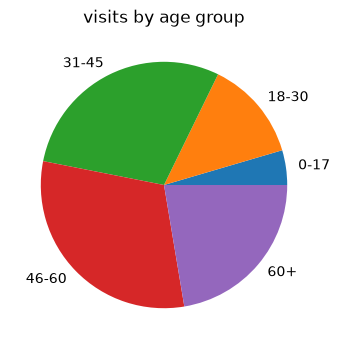

In [223]:
plt.figure(figsize = (7,4))
age_analysis.plot(kind = "pie")
plt.title("visits by age group")
# plt.ylabel("numbers of visists")
plt.show()

## obervation

###### the 40-60 age group contributes the highest numbers of visits , with approximetelt 3,682 visits

#### insight

##### middle-aged and older adults from an important part od hospital demand 

### business recommendation 

#### ensure chronic-care and preventive- healthe services  are sufficenly availabel for the high-utilization age agroup.

## Analysis 2 - What are the most commen chronic condition?

In [200]:
chronic_analysis = df["chronic_condition"].value_counts()
display(chronic_analysis)

chronic_condition
Hypertension    2226
Diabetes        1944
Asthma           906
Cardiac          816
Thyroid          657
Name: count, dtype: int64

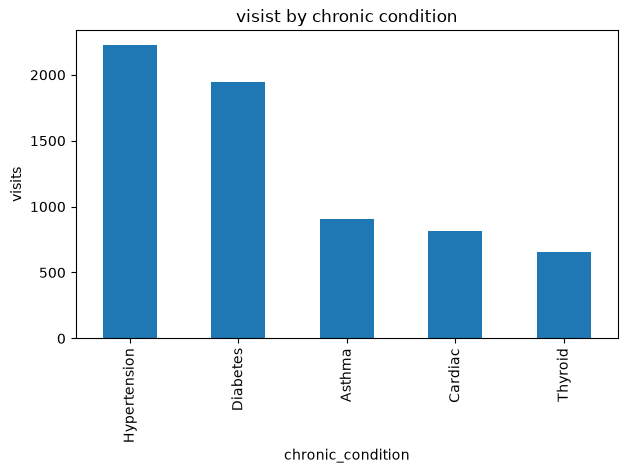

In [233]:
plt.figure(figsize = (7,4))
chronic_analysis.plot(kind = "bar")
plt.title("visist by chronic condition")
plt.ylabel("visits")
plt.show()

#### observation 

##### excluding patients with no chronic condition , hypertension appers most frequernly with around 2,225 visits

### insight 

##### the hospital has meningfull recurring demand related to chronic deisease management 

#### business recommendation 

##### strenthen follow- up programs and appoinment planning for the most common chronic conditions

## Analysis 3 - What is the patient indurance mix

In [202]:
df["insurance_status"].value_counts()

insurance_status
Insured              5990
Self Pay             3886
Government Scheme    2124
Name: count, dtype: int64

In [203]:
df["insurance_status"].value_counts(normalize = True) * 100

insurance_status
Insured              49.916667
Self Pay             32.383333
Government Scheme    17.700000
Name: proportion, dtype: float64

In [204]:
insurance_analysis = (df["insurance_status"].value_counts(normalize = True).mul(100).round(1))

In [205]:
print(insurance_analysis)

insurance_status
Insured              49.9
Self Pay             32.4
Government Scheme    17.7
Name: proportion, dtype: float64


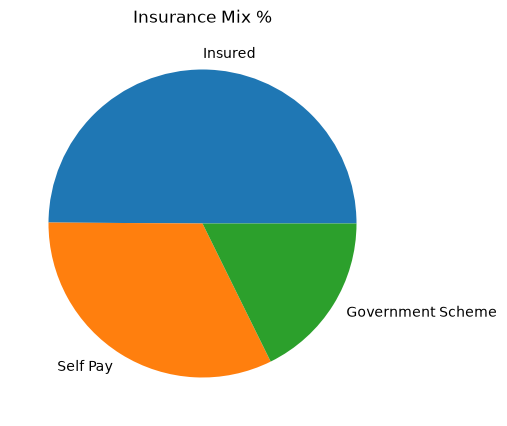

In [239]:
plt.figure(figsize = (10,5))
insurance_analysis.plot(kind = "pie")
plt.title("Insurance Mix %")
plt.ylabel("Percentages of Visits")
plt.show()

#### observation 

##### isured is the largest payer group , representing abount 49.9% of visits

### Insight

##### Hospital Finance is strongly influenced by payer mix

#### Business Recomendation 

#### track the revenue , pending payments and patiets contribustion separately by insurance category

## Analysis 4 - How serious is the waiting-time problem ?

In [207]:
print(df["waiting_time_minutes"].describe().round(2))

count    12000.00
mean        45.39
std         19.07
min          5.00
25%         34.00
50%         44.50
75%         55.00
max        244.00
Name: waiting_time_minutes, dtype: float64


In [208]:
wait_parcentage = (
    df["wait_band"]
    .value_counts(normalize = True)
    .mul(100)
    .round(1)
)

display(wait_parcentage)

wait_band
41-60    45.8
21-40    33.5
60+      14.5
<=20      6.2
Name: proportion, dtype: float64

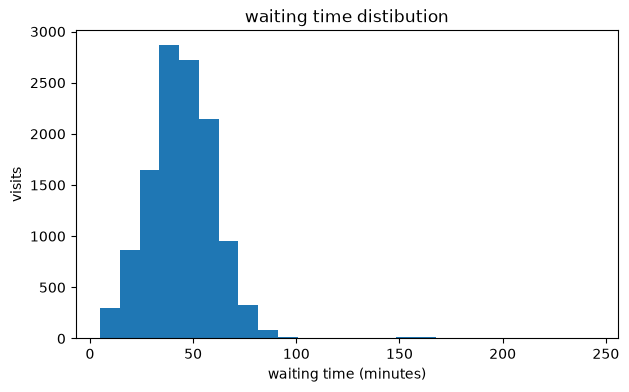

In [209]:
plt.figure(figsize = (7,4))
plt.hist(df["waiting_time_minutes"], bins = 25)
plt.title("waiting time distibution")
plt.xlabel("waiting time (minutes)")
plt.ylabel("visits")
plt.show()

#### obersation 

##### average waiting time is 45.4 minutes and median waiting time is 44.5 minutes approximatelt 15.2% of visits wait more then 60 minutes.

#### insight

##### the waiting-time problem is not limited to a few unusual cases , a noticeable share of patients experience long waits.

#### business recommendation 

##### management should tracj both aveage waitinf time and percentage of visists above 60 miutes.

## Analysis 5 - Which city contributes the most hospital visits?

In [210]:
city_analysis = df["city"].value_counts()
display(city_analysis)

city
Hyderabad       5225
Secunderabad    2040
Warangal        1780
Karimnagar      1523
Nizamabad       1308
Unknown          124
Name: count, dtype: int64

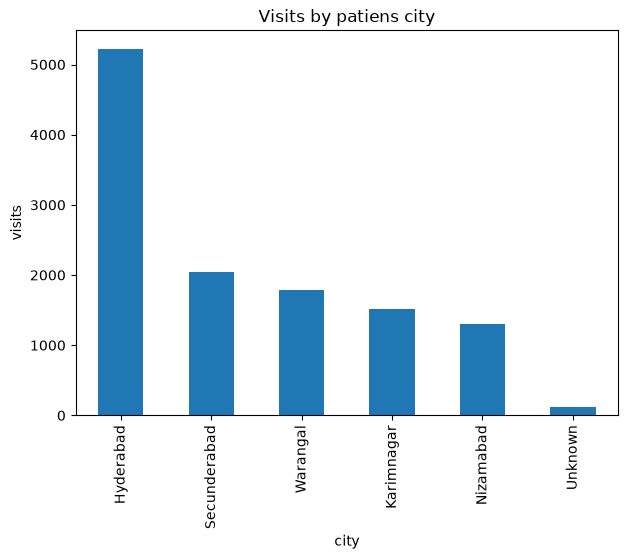

In [211]:
plt.figure(figsize = (7,5))
city_analysis.head(6).plot(kind = "bar")
plt.title("Visits by patiens city")
plt.ylabel("visits")
plt.show()

#### observation 

##### hydarebad contributes the highest number of visits ata apperoximatelt 5,225 visits.

#### insight

##### the hospital has a strong patient concentration in the market.`

#### bussiness recommendation 

##### use city-level demand informarion for outereach clinics , marketing and future serive expansion decision.

In [262]:
department_volume = (
    df['department']
    .value_counts()
)

In [267]:
waiting_satisfaction = (
    df.groupby('wait_band', observed=False)['satisfaction_score']
      .mean()
      .round(2)
)

display(waiting_satisfaction)

wait_band
<=20     4.86
21-40    4.62
41-60    4.34
60+      4.11
Name: satisfaction_score, dtype: float64

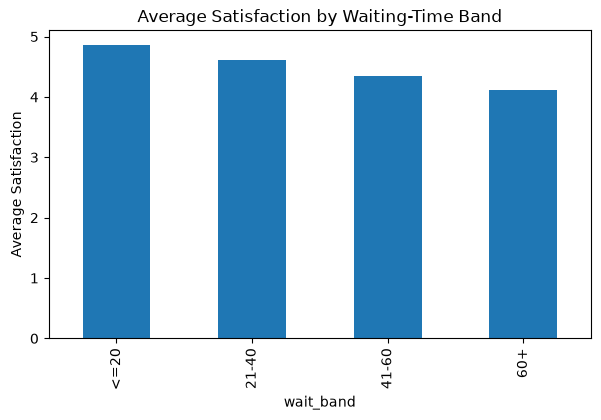

In [271]:
plt.figure(figsize=(7,4))
waiting_satisfaction.plot(kind='bar')
plt.title('Average Satisfaction by Waiting-Time Band')
plt.ylabel('Average Satisfaction')
plt.show()


In [272]:
visit_type_billing = (
    df.groupby('visit_type')
      .agg(
          visits=('visit_id','count'),
          average_bill=('bill_amount','mean'),
          total_revenue=('bill_amount','sum')
      )
      .round(2)
)

display(visit_type_billing)

,visits,average_bill,total_revenue
visit_type,,,
Emergency,2192,4723.14,10353122.15
Inpatient,1718,28640.87,49205013.45
OPD,8090,2397.32,19394352.69


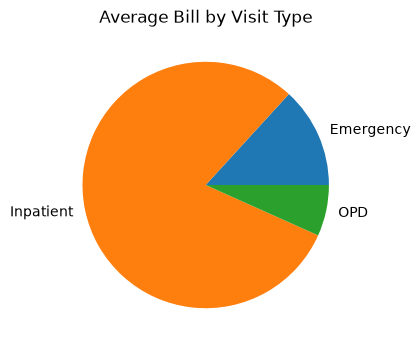

In [275]:
plt.figure(figsize=(6,4))
visit_type_billing['average_bill'].plot(kind='pie')
plt.title('Average Bill by Visit Type')
plt.show()
